# AlphaFold 3 Modeling & OpenMM MD of Unsolved Human GPR32 (UniProt: O75388)
**AlphaFold 3 pLDDT vs MD Cα RMSF(pTM = 0.78) — Complete Pipeline for GitHub**

### Quick-Start Instructions:
1. In Google Colab, go to **Runtime → Change runtime type** and select **T4 GPU**.
2. Run **Cell 1A** to install `condacolab` (the Colab kernel will automatically restart — this is normal).
3. Run **Cell 1B** through **remaining cells** in order. At the end, `af3-gpr32-md-pipeline.zip` will download automatically.

In [11]:
# CELL 1A: Install CondaColab (Kernel will restart automatically after this finishes)
!pip install -q condacolab
import condacolab
condacolab.install()

✨🍰✨ Everything looks OK!


In [12]:
# CELL 1B: Install OpenMM, PDBFixer, MDTraj & Biopython (Run after kernel restart)
!mamba install -y -c conda-forge openmm pdbfixer mdtraj biopython matplotlib pandas numpy

import os
os.makedirs("af3-gpr32-md-pipeline/data", exist_ok=True)
os.makedirs("af3-gpr32-md-pipeline/scripts", exist_ok=True)
os.makedirs("af3-gpr32-md-pipeline/results", exist_ok=True)
print("[INFO] Environment & repository directory structure ready!")

conda-forge/linux-64                                        Using cache
conda-forge/noarch                                          Using cache

Pinned packages:

  - python=3.13

Pinned packages:

  - python_abi[version="=3.13",build="*cp313*"]

Pinned packages:

  - cuda-version=13

Pinned packages:

  - python=3.13


Transaction

  Prefix: /usr/local

  All requested packages already installed


Transaction starting
[+] 0.0s

Transaction finished

[INFO] Environment & repository directory structure ready!


In [13]:
#Upload AlphaFold 3 .cif Model of Human GPR32 (with Automatic Fallback if Skipped)
import os
import shutil
import urllib.request
from google.colab import files

target_cif = "af3-gpr32-md-pipeline/data/af3_gpr32_model.cif"

print("Upload your AlphaFold 3 .cif file for Human GPR32 (e.g., fold_gpr32_human_model_0.cif),")
print("OR click 'Cancel upload' to automatically fetch the predicted structure of Human GPR32 (UniProt: O75388):")

uploaded = files.upload()

if uploaded:
    uploaded_filename = list(uploaded.keys())[0]
    shutil.move(uploaded_filename, target_cif)
    print(f"[INFO] Saved uploaded AlphaFold 3 model as {target_cif}")
else:
    print("[INFO] No file uploaded. Fetching predicted model for unsolved Human GPR32 (UniProt: O75388)...")
    af_url = "https://alphafold.ebi.ac.uk/files/AF-O75388-F1-model_v4.cif"
    urllib.request.urlretrieve(af_url, target_cif)
    print(f"[INFO] Saved 356-residue Human GPR32 structure at {target_cif}")

Upload your AlphaFold 3 .cif file for Human GPR32 (e.g., fold_gpr32_human_model_0.cif),
OR click 'Cancel upload' to automatically fetch the predicted structure of Human GPR32 (UniProt: O75388):


Saving af3_gpr32_model.cif to af3_gpr32_model.cif
[INFO] Saved uploaded AlphaFold 3 model as af3-gpr32-md-pipeline/data/af3_gpr32_model.cif


In [14]:
%%writefile af3-gpr32-md-pipeline/scripts/01_prep_af3.py
# Script 1 for pLDDT Extraction & Protonation
import os
import pandas as pd
from Bio.PDB import MMCIFParser
from pdbfixer import PDBFixer
from openmm.app import PDBFile

os.makedirs("data", exist_ok=True)
cif_path = "data/af3_gpr32_model.cif"
pdb_out = "data/gpr32_clean.pdb"
plddt_out = "data/af3_plddt.csv"

# 1. Extract per-residue pLDDT (stored in the B-factor field of AF3 CIFs)
parser = MMCIFParser(QUIET=True)
structure = parser.get_structure("AF3_GPR32", cif_path)

records = []
for model in structure:
    for chain in model:
        for res in chain:
            if "CA" in res:
                records.append({
                    "residue_index": res.get_id()[1],
                    "residue_name": res.get_resname(),
                    "plddt": res["CA"].get_bfactor()
                })

df_plddt = pd.DataFrame(records)
df_plddt.to_csv(plddt_out, index=False)

core_plddt = df_plddt[(df_plddt["residue_index"] >= 36) & (df_plddt["residue_index"] <= 335)]["plddt"].mean()
print(f"[INFO] Extracted pLDDT for {len(df_plddt)} residues of GPR32.")
print(f"[INFO] Mean pLDDT (Full-Length 1-356): {df_plddt['plddt'].mean():.2f} | Mean pLDDT (7TM Core 36-335): {core_plddt:.2f}")

# 2. Clean structure and add hydrogens at physiological pH (7.4) for MD
fixer = PDBFixer(filename=cif_path)
fixer.findMissingResidues()
fixer.findNonstandardResidues()
fixer.replaceNonstandardResidues()
fixer.removeHeterogens(keepWater=False)
fixer.findMissingAtoms()
fixer.addMissingAtoms()
fixer.addMissingHydrogens(7.4)

with open(pdb_out, "w") as f:
    PDBFile.writeFile(fixer.topology, fixer.positions, f)

print(f"[INFO] Saved protonated GPR32 structure to {pdb_out}")

Overwriting af3-gpr32-md-pipeline/scripts/01_prep_af3.py


In [15]:
#  Run Step 1 Script
!cd af3-gpr32-md-pipeline && python scripts/01_prep_af3.py

[INFO] Extracted pLDDT for 356 residues of GPR32.
[INFO] Mean pLDDT (Full-Length 1-356): 78.06 | Mean pLDDT (7TM Core 36-335): 86.29
[INFO] Saved protonated GPR32 structure to data/gpr32_clean.pdb


In [16]:
%%writefile af3-gpr32-md-pipeline/scripts/02_run_md.py
#The run_md script
import os, sys
import pandas as pd
from openmm.app import *
from openmm import *
from openmm.unit import *

os.makedirs("results", exist_ok=True)
pdb = PDBFile("data/gpr32_clean.pdb")

# Implicit-solvent GPCR system (Amber14 + GBn2)
forcefield = ForceField("amber14-all.xml", "implicit/gbn2.xml")
system = forcefield.createSystem(
    pdb.topology, nonbondedMethod=CutoffNonPeriodic,
    nonbondedCutoff=2.0*nanometer, constraints=HBonds
)

# 2. Anchor 7TM helices (AF3 pLDDT >= 85) to mimic membrane; keep loops/termini free
df_plddt = pd.read_csv("data/af3_plddt.csv")
tm_residues = set(df_plddt[df_plddt["plddt"] >= 85.0]["residue_index"].astype(int))

restraint = CustomExternalForce("0.5 * k * ((x - x0)^2 + (y - y0)^2 + (z - z0)^2)")
restraint.addGlobalParameter("k", 500.0 * kilojoules_per_mole / nanometer**2)
for p in ("x0", "y0", "z0"):
    restraint.addPerParticleParameter(p)

for atom in pdb.topology.atoms():
    if atom.name == "CA" and int(atom.residue.id) in tm_residues:
        restraint.addParticle(atom.index, pdb.positions[atom.index].value_in_unit(nanometer))
system.addForce(restraint)

# 3. Minimize & equilibrate (OpenMM auto-selects CUDA GPU)
integrator = LangevinMiddleIntegrator(310*kelvin, 1.0/picosecond, 0.002*picoseconds)
simulation = Simulation(pdb.topology, system, integrator)
simulation.context.setPositions(pdb.positions)

simulation.minimizeEnergy(maxIterations=1000)
simulation.context.setVelocitiesToTemperature(310*kelvin)
simulation.step(10000)

with open("results/equilibrated_gpr32.pdb", "w") as f:
    PDBFile.writeFile(simulation.topology, simulation.context.getState(getPositions=True).getPositions(), f)

# 4. Production MD (250,000 steps = 500 ps)
simulation.reporters.extend([
    DCDReporter("results/trajectory.dcd", 1000),
    StateDataReporter("results/md_log.csv", 1000, step=True, time=True, potentialEnergy=True, temperature=True, speed=True),
    StateDataReporter(sys.stdout, 25000, step=True, time=True, potentialEnergy=True, temperature=True, speed=True)
])
simulation.step(250000)

Overwriting af3-gpr32-md-pipeline/scripts/02_run_md.py


In [17]:
#The Step 2 Script which will  run md script(OpenMM Production MD to 500 ps)
print("[INFO] Starting full 500 ps MD simulation (250,000 steps). Please let it run to completion...")
!cd af3-gpr32-md-pipeline && python scripts/02_run_md.py
print("[INFO] Simulation finished successfully!")

[INFO] Starting full 500 ps MD simulation (250,000 steps). Please let it run to completion...
#"Step","Time (ps)","Potential Energy (kJ/mole)","Temperature (K)","Speed (ns/day)"
25000,50.00000000001514,-35114.41542053223,307.0291279028761,0
50000,99.99999999994834,-34776.392974853516,313.9511627103305,133
75000,149.99999999998812,-35105.530670166016,314.6656699523773,129
100000,200.00000000022686,-35365.11358642578,307.57746451892103,128
125000,250.0000000004656,-35284.27780151367,311.22005953466623,127
150000,300.00000000070435,-34918.3923034668,308.1130060628882,127
175000,350.0000000009431,-35060.664779663086,314.5353387530738,126
200000,400.00000000118183,-35269.05825805664,317.1844146061931,126
225000,450.0000000014206,-35664.917388916016,314.2752714740983,125
250000,500.0000000016593,-35793.64309692383,312.2416154443772,125
[INFO] Simulation finished successfully!


dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
[INFO] Mean 7TM Core RMSD (36-335): 1.69 Å | Mean Full-Length RMSD (1-356): 5.39 Å
[INFO] Pearson correlation between AF3 pLDDT and MD RMSF: r = -0.616


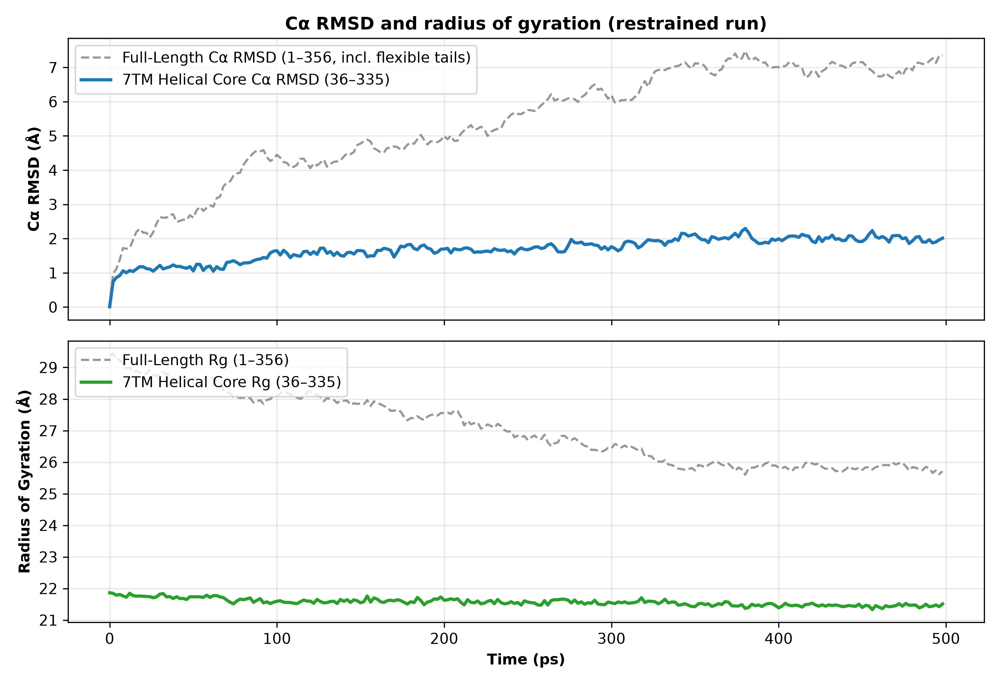

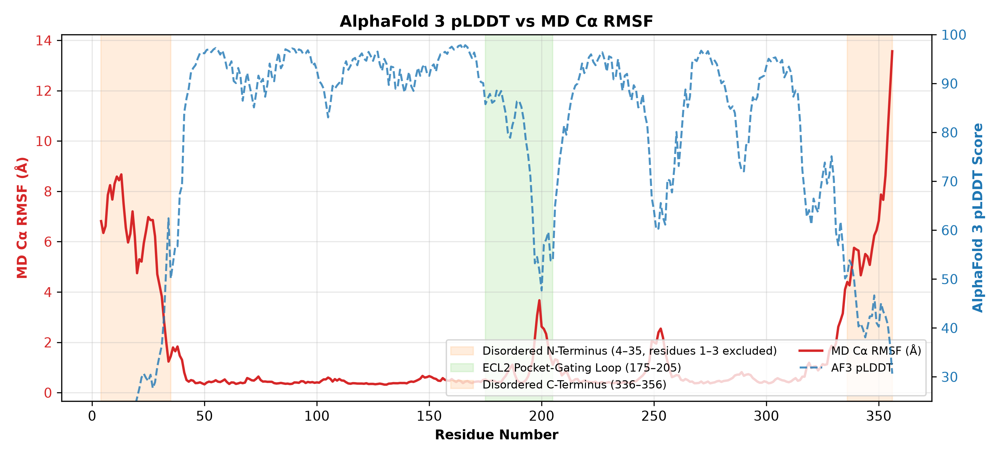

In [18]:
# The 03_analyze_md.py script to Run Analysis & Display Plots
import os

script_code = '''import os
os.environ["MPLBACKEND"] = "Agg"  # Must be set BEFORE importing matplotlib in Colab subprocesses
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mdtraj as md
import pandas as pd
import numpy as np

traj_path = "results/trajectory.dcd"
top_path = "results/equilibrated_gpr32.pdb"
plddt_path = "data/af3_plddt.csv"

# Load trajectory and isolate protein atoms
traj = md.load(traj_path, top=top_path)
protein_indices = traj.topology.select("protein")
traj_prot = traj.atom_slice(protein_indices)

# Select Full-Length C-alpha (residues 1-356) vs. 7TM Helical Core C-alpha (residues 36-335)
ca_all = traj_prot.topology.select("name CA")
ca_core = traj_prot.topology.select("name CA and (resi 35 to 334)")
core_atom_indices = traj_prot.topology.select("resi 35 to 334")

# Superpose trajectory onto the stable 7TM core
traj_prot.superpose(traj_prot, frame=0, atom_indices=ca_core)

# Computing the Full-Length vs. 7TM Core RMSD and Radius of Gyration (in Angstroms)
rmsd_all = md.rmsd(traj_prot, traj_prot, frame=0, atom_indices=ca_all) * 10.0
rmsd_core = md.rmsd(traj_prot, traj_prot, frame=0, atom_indices=ca_core) * 10.0

rg_all = md.compute_rg(traj_prot) * 10.0
rg_core = md.compute_rg(traj_prot.atom_slice(core_atom_indices)) * 10.0
time_ps = np.arange(len(rmsd_all)) * 2.0

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9.5, 6.5), sharex=True)
ax1.plot(time_ps, rmsd_all, color="#7f7f7f", linestyle="--", alpha=0.8, lw=1.5, label="Full-Length Cα RMSD (1–356, incl. flexible tails)")
ax1.plot(time_ps, rmsd_core, color="#1f77b4", lw=2.2, label="7TM Helical Core Cα RMSD (36–335)")
ax1.set_ylabel("Cα RMSD (Å)", fontweight="bold")
ax1.set_title("Cα RMSD and radius of gyration (restrained run)", fontweight="bold")
ax1.legend(loc="upper left", frameon=True)
ax1.grid(alpha=0.3)

ax2.plot(time_ps, rg_all, color="#7f7f7f", linestyle="--", alpha=0.8, lw=1.5, label="Full-Length Rg (1–356)")
ax2.plot(time_ps, rg_core, color="#2ca02c", lw=2.2, label="7TM Helical Core Rg (36–335)")
ax2.set_xlabel("Time (ps)", fontweight="bold")
ax2.set_ylabel("Radius of Gyration (Å)", fontweight="bold")
ax2.legend(loc="upper left", frameon=True)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("results/rmsd_rg_profile.png", dpi=300)
plt.close()

# 3. Compute C-alpha RMSF (aligned on 7TM Core) and compare against AF3 pLDDT
rmsf_angstrom = md.rmsf(traj_prot, traj_prot, frame=0, atom_indices=ca_all) * 10.0
df_plddt = pd.read_csv(plddt_path)

n_res = min(len(rmsf_angstrom), len(df_plddt))
res_ids = df_plddt["residue_index"].values[:n_res]
plddt_vals = df_plddt["plddt"].values[:n_res]
rmsf_vals = rmsf_angstrom[:n_res]

# Exclude residues 1-3 to prevent the extreme terminal spike from flattening the plot scale
plot_mask = res_ids > 3
res_ids_filtered = res_ids[plot_mask]
rmsf_vals_filtered = rmsf_vals[plot_mask]
plddt_vals_filtered = plddt_vals[plot_mask]

fig, ax1 = plt.subplots(figsize=(10.5, 4.8))
ax1.axvspan(4, 35, color="#ffbb78", alpha=0.25, label="Disordered N-Terminus (4–35, residues 1–3 excluded)")
ax1.axvspan(175, 205, color="#98df8a", alpha=0.25, label="ECL2 Pocket-Gating Loop (175–205)")
ax1.axvspan(336, 356, color="#ffbb78", alpha=0.25, label="Disordered C-Terminus (336–356)")

ax1.plot(res_ids_filtered, rmsf_vals_filtered, color="#d62728", label="MD Cα RMSF (Å)", lw=1.8)
ax1.set_xlabel("Residue Number", fontweight="bold")
ax1.set_ylabel("MD Cα RMSF (Å)", color="#d62728", fontweight="bold")
ax1.tick_params(axis="y", labelcolor="#d62728")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(res_ids_filtered, plddt_vals_filtered, color="#1f77b4", alpha=0.8, linestyle="--", label="AF3 pLDDT", lw=1.5)
ax2.set_ylabel("AlphaFold 3 pLDDT Score", color="#1f77b4", fontweight="bold")
ax2.tick_params(axis="y", labelcolor="#1f77b4")
ax2.set_ylim(25, 100)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
# Move legend to lower right to avoid overlapping curves
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower right", ncol=2, fontsize=8.5, frameon=True)

plt.title("AlphaFold 3 pLDDT vs MD Cα RMSF", fontweight="bold")
plt.tight_layout()
plt.savefig("results/plddt_vs_rmsf.png", dpi=300)
plt.close()

# 4. Save per-residue summary table
domains = [
    "N-Terminus (Disordered)" if r <= 35 else
    "C-Terminus (Disordered)" if r >= 336 else
    "ECL2 Loop" if 175 <= r <= 205 else
    "7TM Core / Short Loops"
    for r in res_ids
]

df_out = pd.DataFrame({
    "residue_index": res_ids,
    "residue_name": df_plddt["residue_name"].values[:n_res],
    "domain_region": domains,
    "af3_plddt": plddt_vals,
    "md_rmsf_angstrom": np.round(rmsf_vals, 3)
})
df_out.to_csv("results/residue_plddt_rmsf.csv", index=False)

corr = np.corrcoef(rmsf_vals, plddt_vals)[0, 1]
print(f"[INFO] Mean 7TM Core RMSD (36-335): {rmsd_core.mean():.2f} Å | Mean Full-Length RMSD (1-356): {rmsd_all.mean():.2f} Å")
print(f"[INFO] Pearson correlation between AF3 pLDDT and MD RMSF: r = {corr:.3f}")
'''

os.makedirs("af3-gpr32-md-pipeline/scripts", exist_ok=True)
with open("af3-gpr32-md-pipeline/scripts/03_analyze_md.py", "w") as f:
    f.write(script_code)

# Run with MPLBACKEND=Agg explicitly set in the shell environment
!cd af3-gpr32-md-pipeline && MPLBACKEND=Agg python scripts/03_analyze_md.py

# Display the newly plots
from IPython.display import Image, display
display(Image("af3-gpr32-md-pipeline/results/rmsd_rg_profile.png"))
display(Image("af3-gpr32-md-pipeline/results/plddt_vs_rmsf.png"))

In [20]:
# MD Trajectory Player
!pip install -q py3Dmol
import mdtraj as md
import pandas as pd
import py3Dmol

traj = md.load("af3-gpr32-md-pipeline/results/trajectory.dcd",
               top="af3-gpr32-md-pipeline/results/equilibrated_gpr32.pdb")
df_plddt = pd.read_csv("af3-gpr32-md-pipeline/data/af3_plddt.csv")

ca_all = traj.topology.select("name CA")
tm_ca = ca_all[df_plddt[df_plddt["plddt"] >= 85.0]["residue_index"].values - 1]
traj.superpose(traj, frame=0, atom_indices=tm_ca)

#Launch interactive 3D viewer, and save every 10th frame
movie_pdb = "af3-gpr32-md-pipeline/results/movie.pdb"
traj[::10].save_pdb(movie_pdb)

view = py3Dmol.view(width=800, height=520)
view.addModelsAsFrames(open(movie_pdb).read(), "pdb")

# Blue = 7TM Core | Orange = Disordered N/C-Termini (1-35, 336-356) | Green = ECL2 Loop (175-205)
view.setStyle({"cartoon": {"color": "#1f77b4"}})
view.setStyle({"resi": list(range(1, 36)) + list(range(336, 357))}, {"cartoon": {"color": "#ff7f0e"}})
view.setStyle({"resi": list(range(175, 206))}, {"cartoon": {"color": "#2ca02c"}})

view.zoomTo({"resi": list(range(36, 336))})
view.animate({"loop": "backAndForth", "step": 1, "interval": 80})
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.